In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import ScalarFormatter
%matplotlib inline
import pandas as pd
from planet_cookbook import read_reports as rr
import os
import rebound
import seaborn as sns

sol_to_earth = 332946.078
G = 6.6743* 10**(-11) #N⋅m2/kg2
M_sun = 1.989e+33 #g
AU = 1.496e+13 #cm

In [9]:
params = {
   'axes.labelsize': 15,
   'font.size': 15,
   'legend.fontsize': 10,
   'xtick.labelsize': 15,
   'ytick.labelsize': 15,
   'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15
   }
rcParams.update(params)

In [10]:
#Color-blind friendly pallete
colors = [
    "#0C7BDC",  # Vibrant Blue
    "#E66100",  # Bright Orange
    "#40B0A6",  # Teal/Aqua
    "#8B8D8B",  # Medium Grey
    "#5D3A9B"   # Muted Purple
]

vib_blue = "#0C7BDC"
teal = "#40B0A6"
purple = "#5D3A9B" 

In [11]:
solar_system_df = pd.read_csv('solarsystem.csv')
mercury = solar_system_df[solar_system_df['name'] == 'Mercury']
venus = solar_system_df[solar_system_df['name'] == 'Venus']
earth = solar_system_df[solar_system_df['name'] == 'Earth']
mars = solar_system_df[solar_system_df['name'] == 'Mars']

In [12]:
base_path = "/Users/honeyeah/Codes/data/" #folder with all data


sim_set = "ueda_v5/" #name of simulation set, folder with subfolders the name "sim_set_i"
sim_archive_path = base_path + sim_set + "ueda_v5_" #path given to get_runtime_data function
ueda_v5_rdf = rr.get_runtime_data(sim_archive_path, 50, "ueda_v5_") #rdf is runtime data frame


cut_time = 299.9e6

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed. Binary file was saved with REBOUND Version 4.4.7. You are currently using REBOUND Version 4.4.8.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)


In [13]:
n_runs = 50

maxtimes_ueda_v5 = np.array([
    ueda_v5_rdf[ueda_v5_rdf['simulation_id'] == i + 1]['time'].max()
    for i in range(n_runs)
])

keep_ueda_v5 = np.where(maxtimes_ueda_v5 > 299.9e6)[0]

print("number of finished runs\n")
print(f"ueda_v5: {len(keep_ueda_v5)}")

number of finished runs

ueda_v5: 36


In [14]:
#FOR ueda_v5
cut_times = np.logspace(6, np.log10(299) + 6, 20)
ueda_v5_u_dataframes = []

for cut in cut_times:
    ueda_v5_ppdf_list = rr.get_particle_params_at_time(
        f"/Users/honeyeah/Codes/data/ueda_v5/ueda_v5_", keep_ueda_v5, "ueda_v5_", cut
    )

    ueda_v5_u_pldf_list = []
    for j, i in enumerate(keep_ueda_v5):
        df = rr.read_dbct_output(
        f"/Users/honeyeah/Codes/data/ueda_v5/ueda_v5_{i+1}/animation/uniform_33_{int(cut/1e6)}Myrs.txt",
        0.3, "none", "none"
        )

        df_len = len(df)  
        param_len = len(ueda_v5_ppdf_list[j])
        min_len = min(df_len, param_len)

        if min_len == 0:
            print(f"Skipping index {i}: empty df or param list.")
            continue

        # Trim both to same length
        df = df.iloc[:min_len].copy()
        semi_values = ueda_v5_ppdf_list[j]['semi'][:min_len]
        df['semi'] = semi_values.values  # if semi_values is a Series
        df['sim_id'] = i + 1

        ueda_v5_u_pldf_list.append(df)
        df_at_snapshot = pd.concat(ueda_v5_u_pldf_list)
        df_at_snapshot['time'] = cut
        ueda_v5_u_dataframes.append(df_at_snapshot)

ueda_v5_u_pdframe = pd.concat(ueda_v5_u_dataframes)

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed. Binary file was saved with REBOUND Version 4.4.7. You are currently using REBOUND Version 4.4.8.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: Run

In [15]:
#Step function
ueda_v5_s_dataframes = []

for cut in cut_times:
    ueda_v5_ppdf_list = rr.get_particle_params_at_time(
        f"/Users/honeyeah/Codes/data/ueda_v5/ueda_v5_", keep_ueda_v5, "ueda_v5_", cut
    )

    ueda_v5_s_pldf_list = []
    for j, i in enumerate(keep_ueda_v5):
        df = rr.read_dbct_output(
        f"/Users/honeyeah/Codes/data/ueda_v5/ueda_v5_{i+1}/animation/step_b0.7_p0.20_{int(cut/1e6)}Myrs.txt",
        0.3, "none", "none"
        )

        df_len = len(df)  
        param_len = len(ueda_v5_ppdf_list[j])
        min_len = min(df_len, param_len)

        if min_len == 0:
            print(f"Skipping index {i}: empty df or param list.")
            continue

        # Trim both to same length
        df = df.iloc[:min_len].copy()
        semi_values = ueda_v5_ppdf_list[j]['semi'][:min_len]
        df['semi'] = semi_values.values  # if semi_values is a Series
        df['sim_id'] = i + 1

        ueda_v5_s_pldf_list.append(df)
        df_at_snapshot = pd.concat(ueda_v5_s_pldf_list)
        df_at_snapshot['time'] = cut
        ueda_v5_s_dataframes.append(df_at_snapshot)

ueda_v5_s_pdframe = pd.concat(ueda_v5_s_dataframes)


/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed. Binary file was saved with REBOUND Version 4.4.7. You are currently using REBOUND Version 4.4.8.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: Run

MovieWriter ffmpeg unavailable; using Pillow instead.


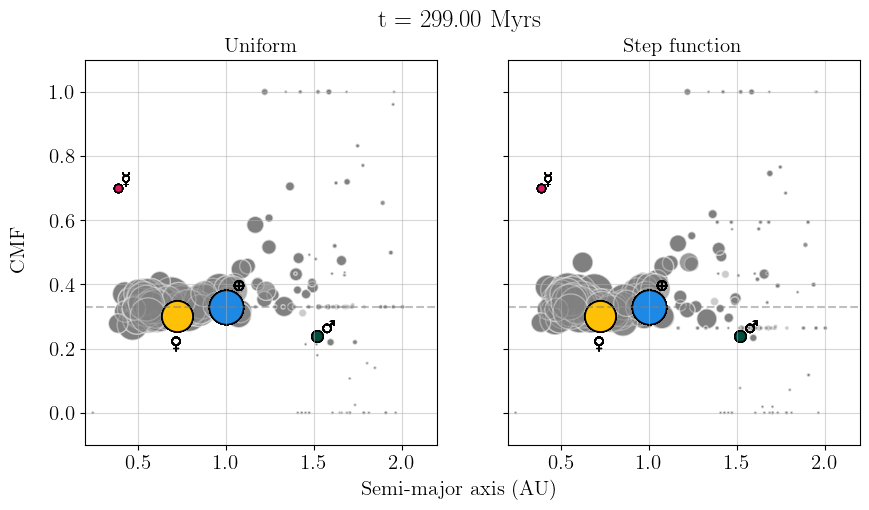

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

dot_scale = 600
col_labels = ["Uniform", "Step function"]

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True, sharex=True)

# set up the axes
for col, ax in enumerate(axes):
    ax.set_xlim(0.2, 2.2)
    ax.set_ylim(-0.1, 1.1)
    ax.grid(True, alpha=0.5)
    ax.plot([0.2, 2.2], [0.33, 0.33], linestyle='dashed', color='grey', alpha=0.5)
    ax.set_title(col_labels[col])

fig.text(0.5, 0.01, 'Semi-major axis (AU)', ha='center')
fig.text(0.05, 0.5, r'CMF', va='center', rotation='vertical')

# scatter artists (placeholders, will be updated)
scatters = [axes[0].scatter([], [], s=[]), axes[1].scatter([], [], s=[])]

def init():
    for sc in scatters:
        sc.set_offsets(np.empty((0, 2)))
        sc.set_sizes([])
    fig.suptitle("")
    return scatters

def update(frame):
    t = cut_times[frame]

    # Select rows for this time
    df_u = ueda_v5_u_pdframe[ueda_v5_u_pdframe['time'] == t]
    df_s = ueda_v5_s_pdframe[ueda_v5_s_pdframe['time'] == t]

    # Update Uniform scatter
    offsets_u = np.column_stack((df_u['semi'], df_u['cmf']))
    scatters[0].set_offsets(offsets_u)
    scatters[0].set_sizes(df_u['mass'] * sol_to_earth * dot_scale)
    scatters[0].set_facecolors("grey")
    scatters[0].set_edgecolors("white")
    scatters[0].set_alpha(0.4)

    # Update Step scatter
    offsets_s = np.column_stack((df_s['semi'], df_s['cmf']))
    scatters[1].set_offsets(offsets_s)
    scatters[1].set_sizes(df_s['mass'] * sol_to_earth * dot_scale)
    scatters[1].set_facecolors("grey")
    scatters[1].set_edgecolors("white")
    scatters[1].set_alpha(0.4)

    # update title
    fig.suptitle(f"t = {t/1e6:.2f} Myrs")

     # --- Add Solar System planets (fixed reference points) ---
    for ax in axes:
        ax.scatter(0.387, 0.7, color='#D81B60', edgecolors='black', linewidths=1,
                   s=0.055 * dot_scale, label='Mercury')
        ax.annotate('☿', [0.4, 0.71], fontsize=12, usetex=False)

        ax.scatter(0.723, 0.3, color='#FFC107', edgecolors='black', linewidths=1,
                   s=0.815 * dot_scale, label='Venus')
        ax.annotate('♀', [0.68, 0.2], fontsize=12, usetex=False)

        ax.scatter(1, 0.33, color='#1E88E5', edgecolors='black', linewidths=1,
                   s=dot_scale, label='Earth')
        ax.annotate('⊕', [1.03, 0.38], fontsize=12, usetex=False)

        ax.scatter(1.52, 0.24, color='#004D40', edgecolors='black', linewidths=1,
                   s=0.107 * dot_scale, label='Mars')
        ax.annotate('♂', [1.54, 0.25], fontsize=12, usetex=False)

    return scatters

ani = FuncAnimation(
    fig, update, frames=len(cut_times), init_func=init,
    blit=False, interval=800, repeat=True
)

# Save if you want
#ani.save("paper_plots/ueda_v5_animation.gif", dpi=200)
ani.save("paper_plots/ueda_v5_animation.gif", dpi=200)

plt.show()
